HISTORICAL SALES DATA
   Month  Sales
0      1    120
1      2    135
2      3    128
3      4    145
4      5    150
5      6    160
6      7    155
7      8    170
8      9    175
9     10    180

ACTUAL SALES:
[265, 270, 285, 300]

PREDICTED SALES:
[258.19, 265.05, 271.91, 278.77]

MODEL EVALUATION
Mean Absolute Error: 11.52
R2 Score: 0.08

FUTURE SALES FORECAST
 Month  Predicted_Sales
    25           285.63
    26           292.49
    27           299.35
    28           306.22
    29           313.08
    30           319.94


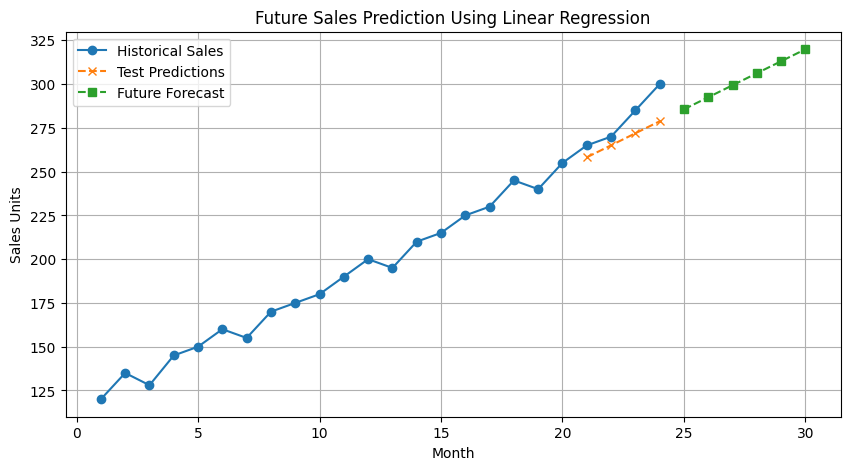


Program executed successfully!


In [21]:

# Future Sales Prediction Using Linear Regression

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Step 1: Create sample historical sales data
data = {
    "Month": list(range(1, 25)),
    "Sales": [
        120, 135, 128, 145, 150, 160,
        155, 170, 175, 180, 190, 200,
        195, 210, 215, 225, 230, 245,
        240, 255, 265, 270, 285, 300
    ]
}

df = pd.DataFrame(data)

print("HISTORICAL SALES DATA")
print(df.head(10))

# Step 2: Prepare input and target
X = df[["Month"]]
y = df["Sales"]

# Step 3: Train Linear Regression model
# Use earlier months to predict later months
split_index = 20

X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

model = LinearRegression()
model.fit(X_train, y_train)

# Step 4: Predict sales for the test months
y_pred = model.predict(X_test)

print("\nACTUAL SALES:")
print(y_test.tolist())

print("\nPREDICTED SALES:")
print(y_pred.round(2).tolist())

# Step 5: Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMODEL EVALUATION")
print("Mean Absolute Error:", round(mae, 2))
print("R2 Score:", round(r2, 2))

# Step 6: Forecast the next 6 months
future_months = pd.DataFrame({
    "Month": list(range(25, 31))
})

future_sales = model.predict(future_months)

forecast = pd.DataFrame({
    "Month": future_months["Month"],
    "Predicted_Sales": future_sales.round(2)
})

print("\nFUTURE SALES FORECAST")
print(forecast.to_string(index=False))

# Step 7: Plot historical and predicted sales
plt.figure(figsize=(10, 5))

plt.plot(
    df["Month"], df["Sales"],
    marker="o", label="Historical Sales"
)

plt.plot(
    X_test["Month"], y_pred,
    marker="x", linestyle="--",
    label="Test Predictions"
)

plt.plot(
    future_months["Month"], future_sales,
    marker="s", linestyle="--",
    label="Future Forecast"
)

plt.xlabel("Month")
plt.ylabel("Sales Units")
plt.title("Future Sales Prediction Using Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

print("\nProgram executed successfully!")
